# Modelo de reforestación — notebook principal

Este notebook es el **punto de entrada** del proyecto. Aquí se explican y ejecutan las decisiones de distribución de especies: geometría simulada, grafo, matriz de competencia, referencia aleatoria, DSATUR, búsqueda local, validación y Monte Carlo espacial.

**Para usarlo:**
1. Descarga el repositorio completo (el notebook utiliza `data/`, `config/` y `reforestacion/`).
2. Abre `modelo_reforestacion.ipynb` desde la **raíz del proyecto** en VS Code o Jupyter.
3. Instala las dependencias una vez con `python -m pip install -r requirements.txt`.
4. En la primera celda de código selecciona `POLIGONOS = 1` (o cualquier ID de 1 a 30) o `POLIGONOS = "todos"`, y ejecuta de arriba hacia abajo. No es necesario editar otra celda para activar los 30. Las figuras y los CSV se guardan en `resultados/`.

Por defecto se usa el ejemplo reproducible **P1**: 1.28 ha, 165 plantas existentes y 677 por añadir (842 totales), con 12 escenarios Monte Carlo espaciales. Los experimentos comparativos extra están **desactivados** para que no se ejecuten sin solicitarlos.

**Alcance:** las posiciones se simulan en un rectángulo de área equivalente y la matriz de competencia es provisional. Reducir el índice J **no demuestra** una mejora de supervivencia. La compra se calcula con inventarios conocidos; la compra estocástica bajo inventario desconocido sigue pendiente.

Las secciones 2–7 definen el modelo, 8–11 construyen y optimizan la asignación, 12–14 validan y comparan, y 15–16 presentan ampliaciones y conclusiones. Las funciones reutilizables se mantienen en `reforestacion/` para evitar duplicar implementaciones.

**Selección única:** las secciones didácticas y sus figuras detallan el primer polígono seleccionado. Si eliges `"todos"`, la sección 15 resuelve automáticamente los 30 y presenta sus resultados y el agregado. `ESCENARIOS_MC` controla el Monte Carlo detallado; `ESCENARIOS_LOTE` controla las repeticiones del lote (1 por defecto para evitar 360 corridas accidentales).


In [1]:
# OPCIONES PRINCIPALES — editar aquí antes de ejecutar todo.
POLIGONOS = 1              # entero de 1 a 30 (p. ej. 25), o "todos"
ESCENARIOS_MC = 12         # Monte Carlo del polígono detallado; usar 2 para probar rápido
ESCENARIOS_LOTE = 1        # escenarios por polígono cuando se elige "todos"
EJECUTAR_COMPARACION_PRESUPUESTOS = False

from pathlib import Path
from dataclasses import replace, asdict
from time import perf_counter
import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Code
from reforestacion.config import Config, perfil
from reforestacion.datos import Datos, cargar_competencia
from reforestacion.geometria import dimensiones, flujos, simular_existentes, candidatas, construir_grafo
from reforestacion.algoritmos import objetivo, base_aleatoria, dsatur, busqueda_local
from reforestacion.validacion import validar_solucion
from reforestacion.experimento import ejecutar_lote, guardar_ejecucion, agregar, seleccionar_poligonos
from reforestacion import visualizacion as vis

ROOT = Path.cwd()
OUT = ROOT/'resultados'
# Separar las figuras de otro polígono para conservar la referencia P1.
if POLIGONOS != 1:
    OUT = OUT/('todos' if POLIGONOS == 'todos' else 'seleccion_'+str(POLIGONOS).replace(' ',''))
OUT.mkdir(parents=True,exist_ok=True)
# La selección se normaliza una vez y gobierna el ejemplo y el lote.
poligonos_ids = seleccionar_poligonos(POLIGONOS)
p = poligonos_ids[0]  # detalle paso a paso y figuras del primer polígono elegido
cfg = perfil('completo', poligonos=tuple(poligonos_ids), escenarios=ESCENARIOS_MC)
cfg_lote = replace(cfg, escenarios=ESCENARIOS_LOTE)  # valida también este presupuesto
print('Polígonos seleccionados:', poligonos_ids)
print(f'Detalle y Monte Carlo: P{p}; escenarios MC: {ESCENARIOS_MC}')
if len(poligonos_ids) > 1:
    print(f'Lote seleccionado: {len(poligonos_ids)} polígonos, {ESCENARIOS_LOTE} escenario(s) por polígono.')
plt.rcParams.update({'font.size':10,'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
def mostrar(fig, nombre):
    fig.savefig(OUT/(nombre+'.png'),dpi=140,bbox_inches='tight')
    plt.show()
    plt.close(fig)
display(pd.Series(asdict(cfg),name='Configuración'))

Polígonos seleccionados: [1]
Detalle y Monte Carlo: P1; escenarios MC: 12


densidad                      658.0
aspecto                         1.0
paso_malla                      3.4
separacion_min                  3.4
radio                           6.0
semilla                    20261014
escenarios                       12
intentos_local                 6000
max_propuestas_posicion      200000
presupuesto                    fijo
intentos_por_nueva               10
poligonos                      (1,)
max_plantas                   20000
max_corridas                    360
diagnosticos                  False
Name: Configuración, dtype: object

## 2. Datos proporcionados por el socio formador
`data/especies.csv`: especie, género, meta por ha y costo unitario. `data/inventario.csv`: área y conteos por especie en 30 polígonos. `data/supervivencia_porcentajes.csv`: contexto histórico, **sin uso como predicción ni como C**. `data/fuentes_sha256.json` registra huellas de documentos originales; no contiene esos documentos y no se usa para regenerar datos.

Los nombres Opuntia engelmannii y Opuntia streptacantha ya están normalizados en CSV. La moneda no está especificada: u.m. P13=5.05 ha es una interpretación editorial pendiente; las etiquetas del mapa no son necesariamente los IDs tabulados. El cargador rechaza duplicados, conteos no enteros, especies ausentes y áreas inconsistentes.

In [2]:
datos = Datos(ROOT)
S = datos.S
area, existentes, cuotas, nuevas = datos.poligono(p,cfg)
tabla = datos.especies.copy()
tabla['existentes'] = existentes
tabla['cuota_final'] = cuotas
tabla['nuevas'] = nuevas
tabla['costo_nuevas_um'] = nuevas * tabla.costo_unitario
display(tabla)
print(f'P{p}: {area} ha; {existentes.sum()} existentes + {nuevas.sum()} nuevas = {cuotas.sum()}')
print(f'30 polígonos: {datos.areas.sum():.2f} ha; adquisición P{p}: {tabla.costo_nuevas_um.sum():.2f} u.m.')

P1: 1.28 ha; 165 existentes + 677 nuevas = 842
30 polígonos: 183.01 ha; adquisición P1: 15903.50 u.m.


,especie,genero,objetivo_por_ha,costo_unitario,existentes,cuota_final,nuevas,costo_nuevas_um
0,Agave lechuguilla,Agave,42,26.0,8,54,46,1196.0
1,Agave salmiana,Agave,196,26.0,46,251,205,5330.0
2,Agave scabra,Agave,42,26.0,16,54,38,988.0
3,Agave striata,Agave,42,26.0,16,54,38,988.0
4,Opuntia cantabrigiensis,Opuntia,49,18.0,11,63,52,936.0
5,Opuntia engelmannii,Opuntia,38,21.0,14,48,34,714.0
6,Opuntia robusta,Opuntia,73,18.0,18,93,75,1350.0
7,Opuntia streptacantha,Opuntia,64,18.0,12,82,70,1260.0
8,Prosopis laevigata,Prosopis,86,26.5,15,110,95,2517.5
9,Yucca filifera,Yucca,26,26.0,9,33,24,624.0


## 3. Conjuntos e índices
Los nodos se identifican por `(polígono, índice local)`; las coordenadas son pares reales $(x,y)$ en metros. El índice local es solo una etiqueta, no una celda binaria de ocupación.

|Símbolo|Significado|Tipo en Python|Unidad|Origen|Equivalente|
|---|---|---|---|---|---|
|$P$|30 polígonos tabulados|lista de int|—|socio|`datos.areas.index`|
|$S$|10 especies|lista de str|—|socio|`datos.S`|
|$F_p$|sitios existentes|array `(nf,2)`|m|simulación, conteos reales|`F`|
|$V_p$|sitios nuevos seleccionados|array `(nv,2)`|m|selección geométrica|`V`|
|$U_p=F_p\cup V_p$|todos los sitios|array `(N,2)`|m|concatenación|`g['U']`|
|$E_p$|pares no dirigidos cercanos|array `(M,2)` de int|—|distancias|`g['pares']`|

En P1 los primeros 165 índices son fijos; los siguientes 677 admiten asignación. Las especies fijas se conocen; **sus coordenadas todavía se simulan**.

In [3]:
display(pd.DataFrame({'conjunto':['P','S',f'F{p}',f'V{p}',f'U{p}'],
    'cardinalidad':[len(datos.areas),len(S),int(existentes.sum()),int(nuevas.sum()),int(cuotas.sum())]}))

,conjunto,cardinalidad
0,P,30
1,S,10
2,F1,165
3,V1,677
4,U1,842


## 4. Parámetros y supuestos
|Símbolo|Significado|Tipo|Unidad|Origen|Python|
|---|---|---|---|---|---|
|$A_p$|área|float|ha|socio|`area`|
|$D$|densidad final objetivo|float|plantas/ha|referencia socio|`cfg.densidad`|
|$T_p$|meta redondeada|int|plantas|regla computacional|`cuotas.sum()`|
|$n_{ps}$|inventario|array int|plantas|socio|`existentes`|
|$R_{ps}$|cuota final|array int|plantas|metas y restos mayores|`cuotas`|
|$q_{ps}=R_{ps}-n_{ps}$|adquisición fija|array int|plantas|derivación|`nuevas`|
|$d_{pij}$|distancia euclidiana|float|m|coordenadas simuladas|`norm(U[i]-U[j])`|
|$d_{min}$|separación ocupada|float|m|supuesto experimental|`cfg.separacion_min`|
|$r$|radio de interacción|float|m|supuesto experimental|`cfg.radio`|
|$C_{st}$|coeficiente competencia|array float|adimensional|supuesto provisional|`C`|
|$w_{pij}$|peso por distancia|array float|adimensional|supuesto|`g['pesos']`|
|$a_{pis}$|especie existente fija|implícita en int|0/1|inventario y permutación|`fijas`|

$T_p=\lfloor A_pD+0.5\rfloor$. Distribuimos $T_p$ según proporciones de las metas por ha: piso y restos mayores, con empates resueltos por orden del catálogo. Si una cuota queda por debajo del inventario, se informa error; no se eliminan plantas.

**P1:** $1.28(658)=842.24$, redondeado a 842. Con 165 existentes hay 677 nuevas. Ni $q$ ni $R$ son decisiones en esta versión. Se usa $d_{min}=3.4$ m y $r=6$ m: funciones distintas.

In [4]:
print('Cuotas:', cuotas.tolist())
print('Compras:', nuevas.tolist())
if p == 1:
    assert (existentes.sum(), nuevas.sum(), cuotas.sum()) == (165,677,842)
else:
    assert np.all(cuotas >= existentes) and cuotas.sum() == existentes.sum() + nuevas.sum()

Cuotas: [54, 251, 54, 54, 63, 48, 93, 82, 110, 33]
Compras: [46, 205, 38, 38, 52, 34, 75, 70, 95, 24]


## 5. Variables de decisión
Para $i\in V_p$:
$$x_{pis}=\begin{cases}1&\text{especie }s\text{ en sitio nuevo }i,\\0&\text{otro caso.}\end{cases}$$
Se define $y_{pis}=a_{pis}$ en $F_p$ y $y_{pis}=x_{pis}$ en $V_p$.

El código almacena una etiqueta entera por planta (`y[i]`), equivalente a una fila one-hot, para ahorrar memoria. Es una representación de **especie asignada**, no un vector de ocupación del terreno. Las coordenadas permanecen en `g['U']`. Por ejemplo, la etiqueta 2 significa la tercera especie del catálogo.

|Símbolo|Significado|Tipo|Unidad|Origen|Python|
|---|---|---|---|---|---|
|$x_{pis}$|Asignación de especie nueva|binario implícito|0/1|decisión heurística|`y[i] == s`, $i\in V_p$|
|$y_{pis}$|Asignación completa|binario implícito|0/1|fija en F, decisión en V|`y[i] == s`|


In [5]:
ejemplo_etiqueta = 2
print('Especie:', S[ejemplo_etiqueta])
print('Fila binaria equivalente:', np.eye(len(S),dtype=int)[ejemplo_etiqueta])

Especie: Agave scabra
Fila binaria equivalente: [0 0 1 0 0 0 0 0 0 0]


## 6. Función objetivo
$$\min J=\sum_{p\in P}\sum_{\{i,j\}\in E_p}w_{pij}\sum_{s\in S}\sum_{t\in S} C_{st}y_{pis}y_{pjt},\qquad
w_{pij}=\max(0,1-d_{pij}/r).$$
Cada par no dirigido aparece **una sola vez**. Como cada sitio tiene una especie, el producto one-hot selecciona $C_{s_i,s_j}$. En código: `sum(pesos * C[y[i], y[j]])`.

$J=J_{FF}+J_{FV}+J_{VV}$; $J_{FF}$ es constante al optimizar un escenario. Dos plantas a 4 m con $r=6$ tienen peso $1/3$; si son de la misma especie y $C_{ss}=3$, su contribución es 1. Esto es un índice, **no una probabilidad de supervivencia**.

In [6]:
display(Code(inspect.getsource(objetivo),language='python'))
print('Ejemplo de una arista:', (1-4/cfg.radio)*3)

Ejemplo de una arista: 1.0


def objetivo(etiquetas,g,C,desglose=False):
    if len(etiquetas)!=len(g['U']) or np.any((etiquetas<0)|(etiquetas>=len(C))):
        raise ValueError('La función objetivo requiere una asignación completa.')
    i,j=g['pares'].T
    valores=g['pesos']*C[etiquetas[i],etiquetas[j]]
    if not desglose:
        return float(valores.sum())
    ff=(i<g['nf'])&(j<g['nf'])
    vv=(i>=g['nf'])&(j>=g['nf'])
    return {'FF':float(valores[ff].sum()),'FV':float(valores[~(ff|vv)].sum()),
            'VV':float(valores[vv].sum()),'total':float(valores.sum())}

## 7. Restricciones
Para cada polígono y especie:
$$\sum_{s\in S}x_{pis}=1\quad(i\in V_p),\qquad
n_{ps}+\sum_{i\in V_p}x_{pis}=R_{ps},$$
$$\sum_s R_{ps}=T_p=|F_p|+|V_p|,\quad y_{pis}=a_{pis}\ (i\in F_p),\quad x_{pis}\in\{0,1\}.$$
Además, $d_{pij}\ge d_{min}$ para todo par ocupado distinto y todos los sitios pertenecen al rectángulo simulado.

**Separación de etapas:** la geometría selecciona exactamente $|V_p|=\sum_s q_{ps}$ sitios compatibles. Después la heurística solo asigna especies; no decide ocupación ni mueve plantas. Permutar etiquetas nuevas conserva las cuotas. Ningún algoritmo garantiza óptimo global o local certificado.

Se corrige la desigualdad $\le1$ del texto antiguo: aquí todos los sitios de $V_p$ deben ocuparse, por lo que corresponde igualdad.

In [7]:
assert np.all(cuotas >= existentes)
assert nuevas.sum() + existentes.sum() == cuotas.sum()
print('Cuotas no negativas y meta conciliada; validaciones espaciales después de construir sitios.')

Cuotas no negativas y meta conciliada; validaciones espaciales después de construir sitios.


## 8. Construcción geométrica de posiciones
El rectángulo tiene superficie $10^4A_p$ m²; aspecto 1 por defecto. Muestreamos posiciones existentes con rechazo por separación y permutamos las especies conservando los conteos. Un límite de propuestas impide ciclos sin fin: agotarlo no prueba imposibilidad matemática.

**Figura 1:** cada símbolo representa una especie en las posiciones simuladas existentes. No son coordenadas observadas. Después generamos una malla triangular de paso 3.4 m, descartamos sitios cercanos a existentes y elegimos por dispersión la cantidad requerida de posiciones nuevas (677 en P1). Este criterio no utiliza C ni especies. Una malla insuficiente produce un fallo registrado, sin relajar distancias.

La densidad ideal de una malla triangular a 3.4 m es diferente de 658 plantas/ha: solo ocupamos parte de la malla. La selección y DSATUR pueden crecer aproximadamente de forma cuadrática; no se guardan matrices completas de distancias.

731 candidatas admisibles; 677 seleccionadas; 842 sitios ocupados.


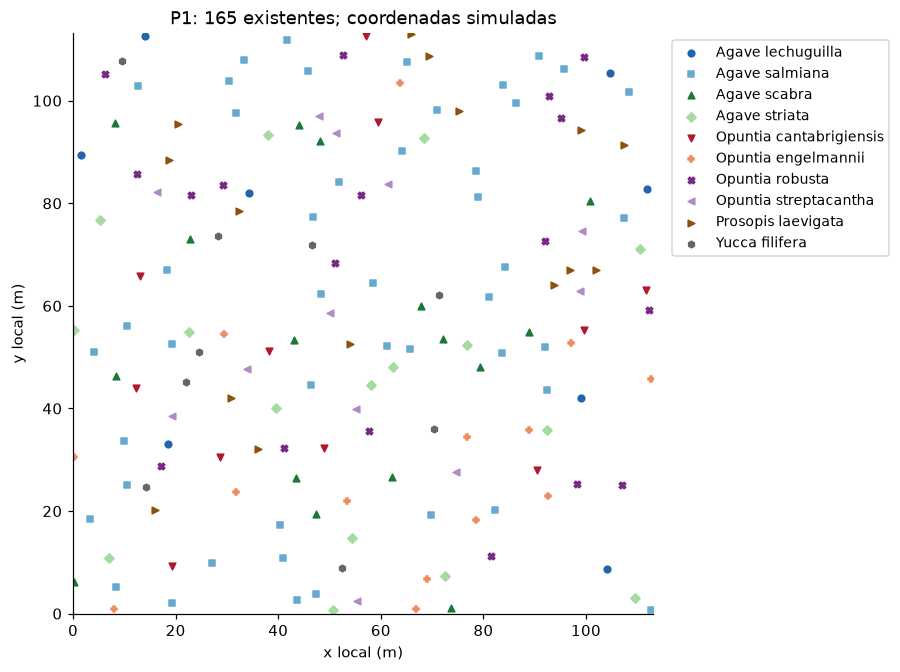

In [8]:
limites = dimensiones(area,cfg)
rng_pos, rng_base, rng_local = flujos(p,0,cfg)
F,fijas = simular_existentes(existentes,limites,cfg,rng_pos)
mostrar(vis.mapa(F,fijas,S,limites,f'P{p}: {len(F)} existentes; coordenadas simuladas'),'01_existentes')
pool,V = candidatas(F,limites,int(nuevas.sum()),cfg)
print(f'{len(pool)} candidatas admisibles; {len(V)} seleccionadas; {len(F)+len(V)} sitios ocupados.')

**Interpretación:** se conservan las etiquetas existentes y se selecciona exactamente el número requerido de sitios nuevos (165 existentes y 677 nuevos en el ejemplo P1). Los espacios vacíos no son decisiones binarias del optimizador de especies.

## 9. Grafo espacial y matriz intercambiable
Conectamos sitios separados a lo más 6 m y guardamos un peso por arista. No hay interacciones entre polígonos.

`config/competencia.json` contiene el orden de especies y una matriz explícita: 3 en la diagonal, 2 entre especies distintas del mismo género y 1 entre géneros diferentes. El cargador valida dimensión, simetría, finitud, no negatividad y orden del catálogo. **Son supuestos**, no mediciones ecológicas.

Más adelante se podría construir C con consumos normalizados de agua y nutrientes, pesos justificados y calibración con datos de campo. Bastaría reemplazar el JSON conservando las propiedades requeridas; no habría que modificar DSATUR ni los deltas.

In [9]:
C = cargar_competencia(ROOT/'config/competencia.json',S)
g = construir_grafo(p,F,V,cfg)
display(pd.DataFrame(C,index=S,columns=S))
print(f"Nodos: {len(g['U'])}; aristas: {len(g['pares'])}")

Nodos: 842; aristas: 3082


,Agave lechuguilla,Agave salmiana,Agave scabra,Agave striata,Opuntia cantabrigiensis,Opuntia engelmannii,Opuntia robusta,Opuntia streptacantha,Prosopis laevigata,Yucca filifera
Agave lechuguilla,3.0,2.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0
Agave salmiana,2.0,3.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0
Agave scabra,2.0,2.0,3.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0
Agave striata,2.0,2.0,2.0,3.0,1.0,1.0,1.0,1.0,1.0,1.0
Opuntia cantabrigiensis,1.0,1.0,1.0,1.0,3.0,2.0,2.0,2.0,1.0,1.0
Opuntia engelmannii,1.0,1.0,1.0,1.0,2.0,3.0,2.0,2.0,1.0,1.0
Opuntia robusta,1.0,1.0,1.0,1.0,2.0,2.0,3.0,2.0,1.0,1.0
Opuntia streptacantha,1.0,1.0,1.0,1.0,2.0,2.0,2.0,3.0,1.0,1.0
Prosopis laevigata,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,3.0,1.0
Yucca filifera,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,3.0


## 10. Referencia aleatoria y DSATUR adaptado
La referencia permuta el multiconjunto de especies nuevas: es factible y usa idénticos sitios y cuotas. DSATUR elige el siguiente vértice por saturación (número de especies distintas entre vecinos asignados), luego grado ponderado y menor índice.

Para cada especie disponible calcula $\Delta_i(s)=\sum_{j\in N(i),j\ asignado}w_{ij}C_{s,s_j}$; escoge menor costo incremental, mayor cuota pendiente y menor índice de especie, en ese orden. **No es coloreo propio:** repetir especies se permite con penalización. Como todas las especies pueden ocupar cualquier sitio nuevo y las cuotas suman vacantes, siempre hay especie disponible.

La implementación extraída se muestra para poder relacionar saturación, costos y cuotas con el código. Los desempates y el orden de aristas se conservan del prototipo.

In [10]:
display(Code(inspect.getsource(dsatur),language='python'))
t0=perf_counter();y_base=base_aleatoria(fijas,nuevas,rng_base);t_base=perf_counter()-t0
t0=perf_counter();y_dsatur=dsatur(fijas,nuevas,g,C);t_dsatur=perf_counter()-t0
print(f'Aleatoria: {objetivo(y_base,g,C):.3f}; DSATUR: {objetivo(y_dsatur,g,C):.3f}')

Aleatoria: 1089.007; DSATUR: 991.748


def dsatur(fijas,q,g,C):
    validar_C(C)
    nf,N=len(fijas),len(g['U'])
    if len(q)!=len(C) or np.any(q<0) or np.any(q%1) or int(q.sum())!=N-nf:
        raise ValueError('Cuotas inválidas o incompatibles con el número de posiciones.')
    y=np.full(N,-1,dtype=int)
    y[:nf]=fijas
    restante=q.astype(int).copy()
    vistos=np.zeros((N,len(C)),dtype=bool)
    coste=np.zeros((N,len(C)))
    grado=np.array([sum(w for _,w in ad) for ad in g['ady']])
    def actualizar(i,s):
        for j,w in g['ady'][i]:
            if y[j]<0:
                vistos[j,s]=True
                coste[j]+=w*C[:,s]
    for i,s in enumerate(fijas):
        actualizar(i,int(s))
    for _ in range(N-nf):
        libres=np.flatnonzero(y<0)
        saturacion=vistos[libres].sum(axis=1)
        i=int(libres[np.lexsort((libres,-grado[libres],-saturacion))[0]])
        factibles=np.flatnonzero(restante>0)
        if not len(factibles):
            raise ValueError('No queda especie factible.')
        s=int(min(factibles,key=lambda s:(coste[i,s],-restante[s],s)))
        y[i]=s
        restante[s]-=1
        actualizar(i,s)
    assert not restante.any()
    return y

## 11. DSATUR + búsqueda local
1. Proponer dos sitios **nuevos distintos** uniformemente al azar.
2. Si tienen la misma especie, contar y descartar la propuesta.
3. Evaluar $\Delta J$ sumando aristas incidentes. La arista entre ambos sitios no cambia porque C es simétrica.
4. Intercambiar solo si hay mejora negativa. Se conserva la tolerancia histórica: $\Delta J<-10^{-10}$, para descartar empates de coma flotante.

Nunca se modifican plantas existentes. Cuotas y coordenadas quedan fijas. El presupuesto cuenta propuestas, incluidas las descartadas; terminarlo no certifica óptimo local.

El diagnóstico opcional de trayectoria tiene **propuestas en X y J en Y**. Descensos = mejoras aceptadas; mesetas = sin mejora aceptada. Incluye la meseta hasta la última propuesta. Se muestran contadores que satisfacen propuestas = iguales + evaluados y evaluados = aceptados + rechazados.

In [11]:
display(Code(inspect.getsource(busqueda_local),language='python'))
y_final,historia,stats = busqueda_local(y_dsatur,g,C,rng_local,cfg.intentos(len(V)))
display(pd.Series(stats,name='Búsqueda local'))
detalle = dict(g=g,F=F,V=V,fijas=fijas,limites=limites,historia=historia)
if cfg.diagnosticos:
    for nombre,fig in vis.diagnosticos(detalle,C,S):
        mostrar(fig,'diagnostico_'+nombre)

def busqueda_local(inicial,g,C,rng,intentos):
    validar_C(C)
    if not isinstance(intentos, int) or intentos < 0:
        raise ValueError('Intentos debe ser entero no negativo.')
    inicio = perf_counter()
    iguales = evaluados = aceptados = 0
    y=inicial.copy()
    valor=objetivo(y,g,C)
    historia=[(0,valor)]
    movibles=np.arange(g['nf'],len(y))
    propuestas = intentos if len(movibles) >= 2 else 0
    for intento in range(1,propuestas+1):
        a,b=rng.choice(movibles,2,replace=False)
        if y[a]==y[b]:
            iguales += 1
            continue
        evaluados += 1
        delta=delta_intercambio(a,b,y,g,C)
        if delta < -1e-10:  # tolerancia original: descartar empates numéricos
            aceptados += 1
            y[a],y[b]=y[b],y[a]
            valor+=delta
            historia.append((intento,valor))
    assert np.isclose(valor,objetivo(y,g,C),atol=1e-7)
    final = objetivo(y,g,C)
    estadisticas = dict(propuestas=propuestas, especies_iguales=iguales,
        evaluados=evaluados, aceptados=aceptados, rechazados=evaluados-aceptados,
        J_inicial=historia[0][1], J_final=final,
        mejora_local_pct=100*(historia[0][1]-final)/historia[0][1] if historia[0][1] else 0.,
        segundos=perf_counter()-inicio)
    # Extender hasta el presupuesto permite ver la meseta final.
    if historia[-1][0] != propuestas:
        historia.append((propuestas, final))
    return y,np.array(historia),estadisticas

propuestas          6000.000000
especies_iguales     904.000000
evaluados           5096.000000
aceptados            283.000000
rechazados          4813.000000
J_inicial            991.747705
J_final              874.525183
mejora_local_pct      11.819793
segundos               0.078106
Name: Búsqueda local, dtype: float64

**Interpretación:** el número de aceptados es menor que el de evaluados; el índice final puede disminuir sin modificar las compras. Los cinco diagnósticos opcionales se activan con `diagnosticos=True` en la configuración.

## 12. Validación de las soluciones
La siguiente celda comprueba cuotas, plantas existentes, meta total, pertenencia al terreno y separación mínima para los tres métodos. También calcula J directamente desde las aristas, comprueba los contadores de búsqueda local y verifica que la mejora no aumente J.

Estas verificaciones forman parte del notebook principal. La batería adicional de 15 pruebas automatizadas y su documentación se conserva en el **historial de Git** anterior a la simplificación; no hace falta una carpeta `tests/` para ejecutar este notebook.


In [12]:
for y in (y_base,y_dsatur,y_final):
    validar_solucion(y,g,fijas,existentes,cuotas,limites,cfg)
assert np.array_equal(g['U'][:len(F)],F)
j_directo = sum(a['weight']*C[y_final[i[1]],y_final[j[1]]] for i,j,a in g['G'].edges(data=True))
assert np.isclose(j_directo,objetivo(y_final,g,C))
assert stats['propuestas'] == stats['especies_iguales']+stats['evaluados']
assert stats['evaluados'] == stats['aceptados']+stats['rechazados']
assert objetivo(y_final,g,C) <= objetivo(y_dsatur,g,C)+1e-8
print('Las tres soluciones cumplen restricciones; evaluación directa e incremental consistentes.')

Las tres soluciones cumplen restricciones; evaluación directa e incremental consistentes.


## 13. Resultados y comparación de métodos
**Figura 2:** distribución final; anillos negros distinguen existentes. Las coordenadas se conservaron al optimizar. **Figura 3:** los índices de los tres métodos corresponden al mismo escenario 0, no a terrenos diferentes. Menor J significa menor penalización bajo C provisional; no mide supervivencia.

Reducción frente a aleatoria: 19.70%


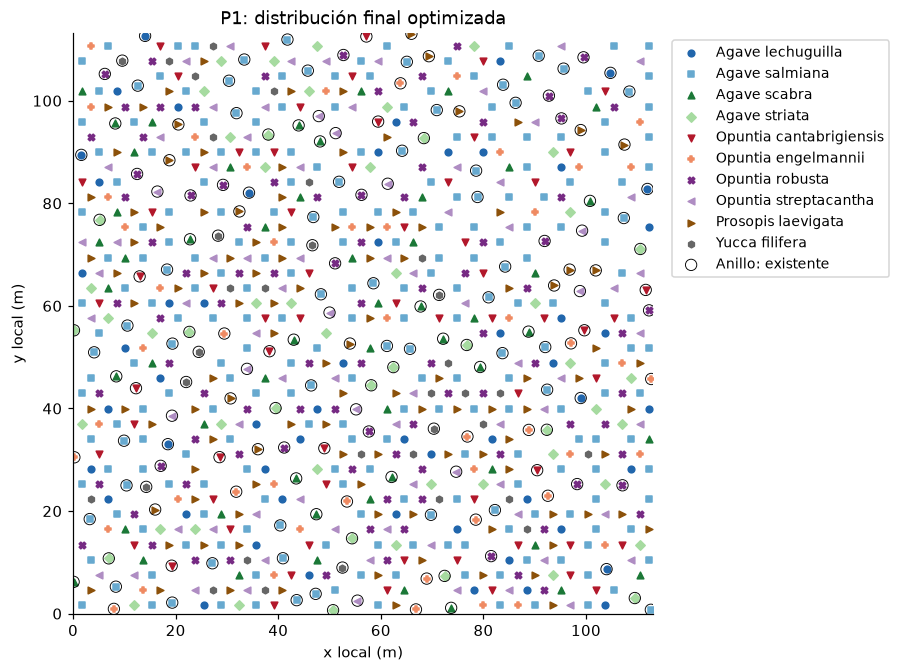

,metodo,J,FF,FV,VV,total,segundos_asignacion
0,Aleatoria,1089.0066,23.1772,218.8182,847.0112,1089.0066,0.0002
1,DSATUR,991.7477,23.1772,190.9961,777.5743,991.7477,0.0305
2,DSATUR + local,874.5252,23.1772,195.3119,656.0360,874.5252,0.1086


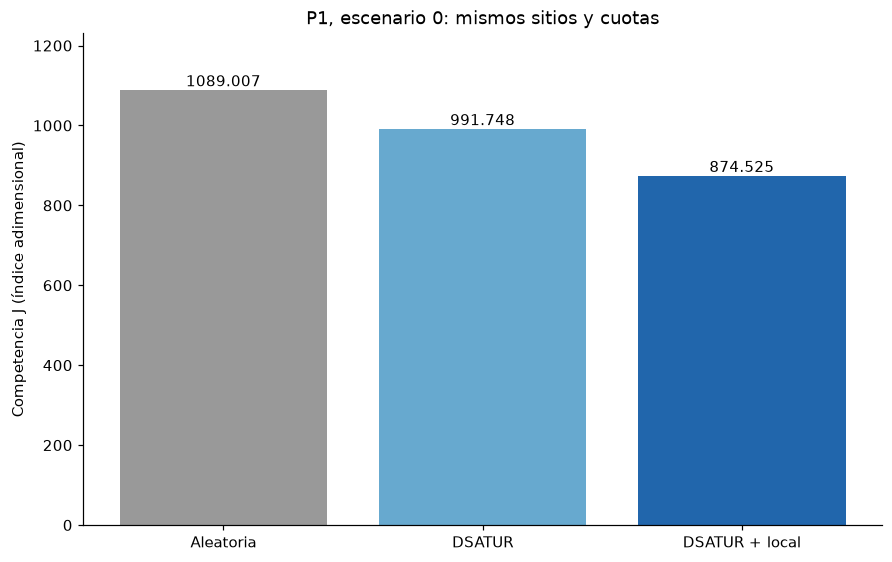

In [13]:
mostrar(vis.mapa(g['U'],y_final,S,limites,f'P{p}: distribución final optimizada',nf=len(F)),'02_final')
comparacion = pd.DataFrame([dict(metodo=nombre,J=objetivo(y,g,C),**objetivo(y,g,C,True),segundos_asignacion=tiempo)
    for nombre,y,tiempo in [('Aleatoria',y_base,t_base),('DSATUR',y_dsatur,t_dsatur),('DSATUR + local',y_final,t_dsatur+stats['segundos'])]])
display(comparacion.round(4))
mostrar(vis.comparacion(comparacion,f'P{p}, escenario 0: mismos sitios y cuotas'),'03_comparacion')
comparacion.to_csv(OUT/f'comparacion_p{p}.csv',index=False)
pd.DataFrame({'indice':np.arange(len(y_final)),'x_m':g['U'][:,0],'y_m':g['U'][:,1],
    'existente':np.arange(len(y_final))<len(F),'especie':[S[s] for s in y_final]}).to_csv(OUT/f'distribucion_p{p}.csv',index=False)
print(f'Reducción frente a aleatoria: {100*(1-objetivo(y_final,g,C)/objetivo(y_base,g,C)):.2f}%')

**Interpretación P1:** la referencia esperada es 1089.007, DSATUR 991.748 y DSATUR + local 874.525 con las semillas y versiones fijadas. La tabla anterior contiene los valores efectivamente ejecutados y separa el término fijo FF.

## 14. Monte Carlo espacial
Cada corrida es un **escenario espacial completo** del polígono detallado, con los mismos conteos de inventario y nuevas plantas. En la configuración inicial P1 son 12 escenarios con 165 existentes y 677 nuevas cada uno. No son doce posiciones individuales. Se regeneran posiciones y se aplican nuevamente los métodos; cada resultado se adapta a su escenario.

Los conteos y compras siguen fijos. La variación mezcla geometría, referencia aleatoria y propuestas locales: no modela incertidumbre sobre cuánto comprar ni valida ecología. DSATUR es determinista dado el grafo. Los flujos dependen de `(semilla,p,escenario)`, por lo que cambiar el orden del lote no cambia soluciones.

**Figura 4:** comparación pareada y distribución empírica de reducciones. Fallos no se sustituyen ni se ocultan; las estadísticas se condicionan a los completados. Percentiles son descriptivos, no intervalos de confianza. Los tiempos dependen del equipo.

Completados 12/12; fallos u omisiones: 0


,poligono,escenario,estado,detalle,J_base,J_dsatur,J_final,mejora_pct
0,1,0,ok,,1089.0066,991.7477,874.5252,19.6951
1,1,1,ok,,1122.5587,993.4642,885.3773,21.1286
2,1,2,ok,,1125.4928,997.7077,892.0973,20.7372
3,1,3,ok,,1112.0318,986.0190,884.1752,20.4901
4,1,4,ok,,1107.1937,1010.0877,891.9297,19.4423
5,1,5,ok,,1090.7458,977.9076,877.7682,19.5259
6,1,6,ok,,1091.9162,985.1785,880.3646,19.3743
7,1,7,ok,,1106.4877,963.9692,871.4324,21.2434
8,1,8,ok,,1103.1078,975.0654,876.3436,20.5568
9,1,9,ok,,1114.3159,995.8442,894.5339,19.7235


,count,mean,std,min,max,error_estandar_media
J_base,12.0,1105.7434,12.8867,1089.0066,1125.4928,3.7201
J_dsatur,12.0,988.4515,12.0131,963.9692,1010.0877,3.4679
J_final,12.0,882.8562,7.3704,871.4324,894.5339,2.1276
mejora_pct,12.0,20.1518,0.7221,19.2457,21.2434,0.2085


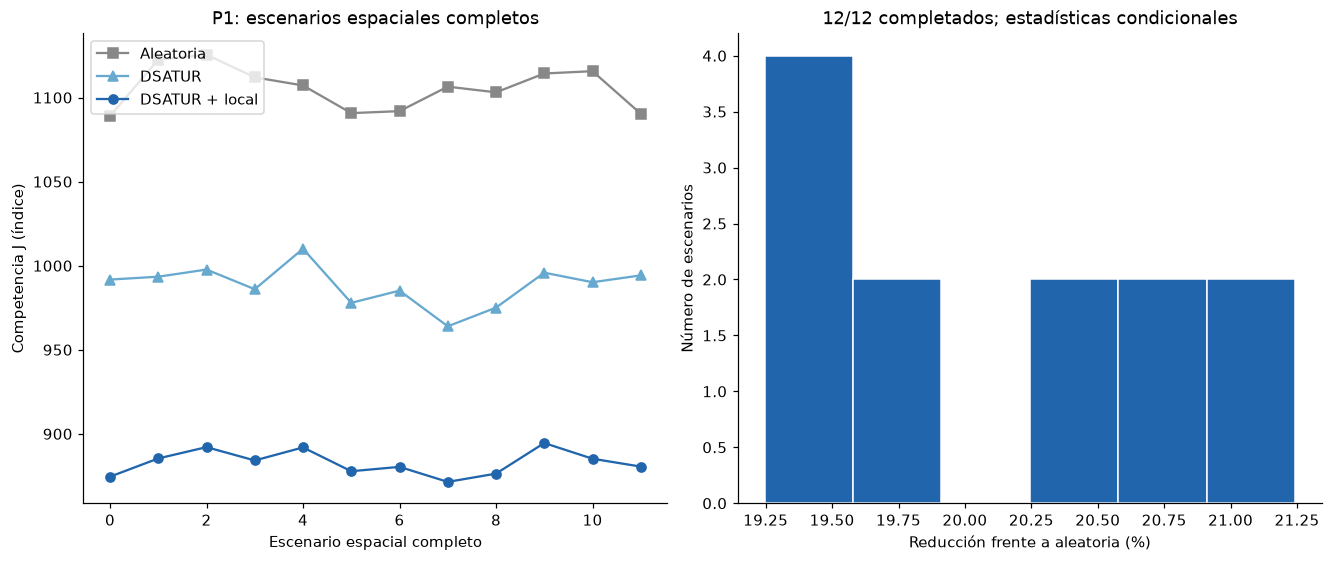

In [14]:
cfg_mc = replace(cfg,poligonos=(p,))
mc = ejecutar_lote(datos,cfg_mc,C)
guardar_ejecucion(OUT/f'monte_carlo_p{p}',datos,cfg_mc,C,mc)
display(mc.reindex(columns=['poligono','escenario','estado','detalle','J_base','J_dsatur','J_final','mejora_pct']).round(4))
ok = mc.loc[mc.estado.eq('ok')]
print(f'Completados {len(ok)}/{len(mc)}; fallos u omisiones: {len(mc)-len(ok)}')
if not ok.empty:
    resumen = ok[['J_base','J_dsatur','J_final','mejora_pct']].agg(['count','mean','std','min','max']).T
    resumen['error_estandar_media'] = resumen['std']/np.sqrt(resumen['count'])
    display(resumen.round(4))
    resumen.to_csv(OUT/f'estadisticas_mc_p{p}.csv')
mostrar(vis.monte_carlo(mc,f'P{p}: escenarios espaciales completos'),'04_monte_carlo')

**Interpretación:** el denominador de escenarios completados forma parte del resultado. Con la configuración original P1, el historial registra 12/12 escenarios y una reducción media del 20.15%; la tabla anterior permite repetir esa comprobación. No extrapolar el índice a supervivencia. Si reduces `ESCENARIOS_MC`, las estadísticas se recalcularán con menos escenarios.

### Experimento opcional: presupuesto de búsqueda local
La celda siguiente está desactivada por defecto. Al establecer `EJECUTAR_COMPARACION_PRESUPUESTOS = True` en la primera celda, compara sobre tres escenarios las mismas semillas con 6000 propuestas fijas frente a `10 ×` nuevas propuestas. En P1 equivale a 6770 propuestas proporcionales. No se garantiza que el mayor presupuesto mejore en todos los casos.


In [15]:
if EJECUTAR_COMPARACION_PRESUPUESTOS:
    presupuestos = []
    for modo in ('fijo', 'proporcional'):
        config_presupuesto = replace(cfg, poligonos=(p,), escenarios=3, presupuesto=modo)
        ensayo = ejecutar_lote(datos, config_presupuesto, C)
        guardar_ejecucion(OUT/('presupuesto_'+modo), datos, config_presupuesto, C, ensayo)
        ensayo['presupuesto'] = modo
        presupuestos.append(ensayo)
    presupuestos = pd.concat(presupuestos, ignore_index=True)
    display(presupuestos[['escenario','presupuesto','estado','local_propuestas',
                          'local_aceptados','J_final','seg_local']].round(4))
else:
    print('Comparación de presupuestos omitida (opcional).')


Comparación de presupuestos omitida (opcional).


## 15. Resolución de los polígonos seleccionados al inicio
Cada polígono se resuelve independientemente, sin aristas ni intercambios entre polígonos.

- Si `POLIGONOS` es un entero (1–30), las secciones anteriores resuelven ese polígono y su Monte Carlo; esta celda muestra su escenario 0 sin volver a optimizarlo.
- Si `POLIGONOS = "todos"`, esta celda ejecuta automáticamente P1–P30, con `ESCENARIOS_LOTE` repeticiones por polígono. No hay otro interruptor que activar aquí. Las gráficas didácticas anteriores corresponden a P1, el primero de la selección; la tabla siguiente contiene todos.

El lote usa las mismas semillas y heurística, con los límites del perfil completo (20000 plantas por polígono, máximo 360 corridas). Las omisiones y fallos se conservan con su motivo. Los agregados suman solo polígonos completados dentro de cada escenario y muestran su número: no se confunden escenarios con terrenos diferentes.

**Referencia histórica:** con un escenario por polígono, los 30 se completaron con J agregado 161430.286548 (aleatoria), 146407.918776 (DSATUR) y 134245.194845 (local). La tabla ejecutada indica los resultados de esta ejecución. Las cuotas de los 30 se revisan siempre, sin afirmar que se optimizaron IDs no seleccionados.


In [16]:
if len(poligonos_ids) > 1:
    # cfg_lote procede exclusivamente de las opciones de la primera celda.
    lote = ejecutar_lote(datos, cfg_lote, C)
    guardar_ejecucion(OUT/'lote_seleccionado', datos, cfg_lote, C, lote)
else:
    # El escenario 0 del polígono elegido ya fue resuelto en Monte Carlo.
    lote = mc.loc[mc.escenario.eq(0)].copy()
print('Polígonos solicitados:', poligonos_ids)
display(lote.reindex(columns=['poligono','escenario','estado','detalle','total',
                              'J_base','J_dsatur','J_final','seg_total']).round(4))
display(agregar(lote).round(4))
print('Estados del lote:', lote.estado.value_counts().to_dict())
resumen_30 = datos.resumen(cfg)
print('Inventario y cuotas de los 30 polígonos:',
      resumen_30[['existentes','meta_final','nuevas']].sum().to_dict())


Polígonos solicitados: [1]
Estados del lote: {'ok': 1}
Inventario y cuotas de los 30 polígonos: {'existentes': 23569, 'meta_final': 120419, 'nuevas': 96850}


,poligono,escenario,estado,detalle,total,J_base,J_dsatur,J_final,seg_total
0,1,0,ok,,842,1089.0066,991.7477,874.5252,0.1466


,escenario,existentes,nuevas,total,J_base,J_dsatur,J_final,costo_um,poligonos_completados,mejora_pct
0,0,165,677,842,1089.0066,991.7477,874.5252,15903.5,1,19.6951


## 16. Conclusiones y siguientes pasos

- La solución respeta cuotas por especie, la inmovilidad de plantas existentes y la separación mínima de los sitios simulados.
- DSATUR utiliza la competencia entre especies y la estructura del grafo; la búsqueda local solo acepta intercambios con mejora del índice J. La referencia aleatoria usa exactamente los mismos sitios y cantidades.
- `resultados/` contiene las cuatro gráficas principales de referencia P1 y los CSV más relevantes. Otras selecciones guardan sus figuras en subcarpetas para no sobrescribir esa referencia. Los subdirectorios temporales se crean al ejecutar experimentos; no es necesario mantenerlos versionados.
- `README.md` resume instalación, estructura, resultados validados y limitaciones. El historial de Git conserva los scripts auxiliares, pruebas y evidencia detallada del prototipo anterior.

**Limitaciones:** geometría rectangular y coordenadas simuladas; matriz de competencia provisional; distancias uniformes; sin suelo, pendiente ni agua medidos; no se demuestra optimalidad ni mejora de supervivencia. No se incorporan compras probabilísticas, supervivencia temporal ni cadenas de Markov.

**Pendientes:** validar matriz con información ecológica, comprobar áreas/identificadores de los polígonos, y modelar cantidades a comprar cuando el inventario existente es incierto.


In [17]:
if not ok.empty:
    display(Markdown(
        f"**P{p} (detalle):** {len(ok)}/{len(mc)} escenarios completos; "
        f"reducción media **{ok.mejora_pct.mean():.2f}%** del índice "
        f"frente a aleatoria. Compra fija: **{tabla.costo_nuevas_um.sum():.2f} u.m.**"
    ))
print('Selección solicitada:', poligonos_ids)
print('Polígonos con al menos un escenario completado:',
      sorted(lote.loc[lote.estado.eq('ok'),'poligono'].unique().tolist()))
print('Estados del lote:', lote.estado.value_counts().to_dict())
print('Resultados principales en:', OUT.relative_to(ROOT))


Selección solicitada: [1]
Polígonos con al menos un escenario completado: [1]
Estados del lote: {'ok': 1}
Resultados principales en: resultados


**P1 (detalle):** 12/12 escenarios completos; reducción media **20.15%** del índice frente a aleatoria. Compra fija: **15903.50 u.m.**